In [2]:
%load_ext autoreload
%autoreload 2
# autoreload means edits to the .py files in functions/ are picked up without restarting the kernel

import numpy as np
import matplotlib.pyplot as plt

from functions import (
    local_action,
    metropolis_sweep,
    harmonic,
    anharmonic,
    naive_error,
    integrated_auto_correlation,
    correlation,
    jackknife,
    energy_gap,
)

In [3]:
#class MonteCarloAnalysis:
    #def __init()

Acceptance rate = 0.8295923809523809

<x>   = -0.0029 ± 0.0069  (naive 0.0010)       theoretical value within range: True
<x^2> = 0.4473 ± 0.0042  (naive 0.0007)       theoretical value within range: True
tau_int(x)   = 24.43  (W=123),  N_eff = 205
tau_int(x^2) = 17.32  (W=87),  N_eff = 289
<x> is 0.42 true standard errors from 0
<x^2> is 0.01 true standard errors from the analytical value 0.447


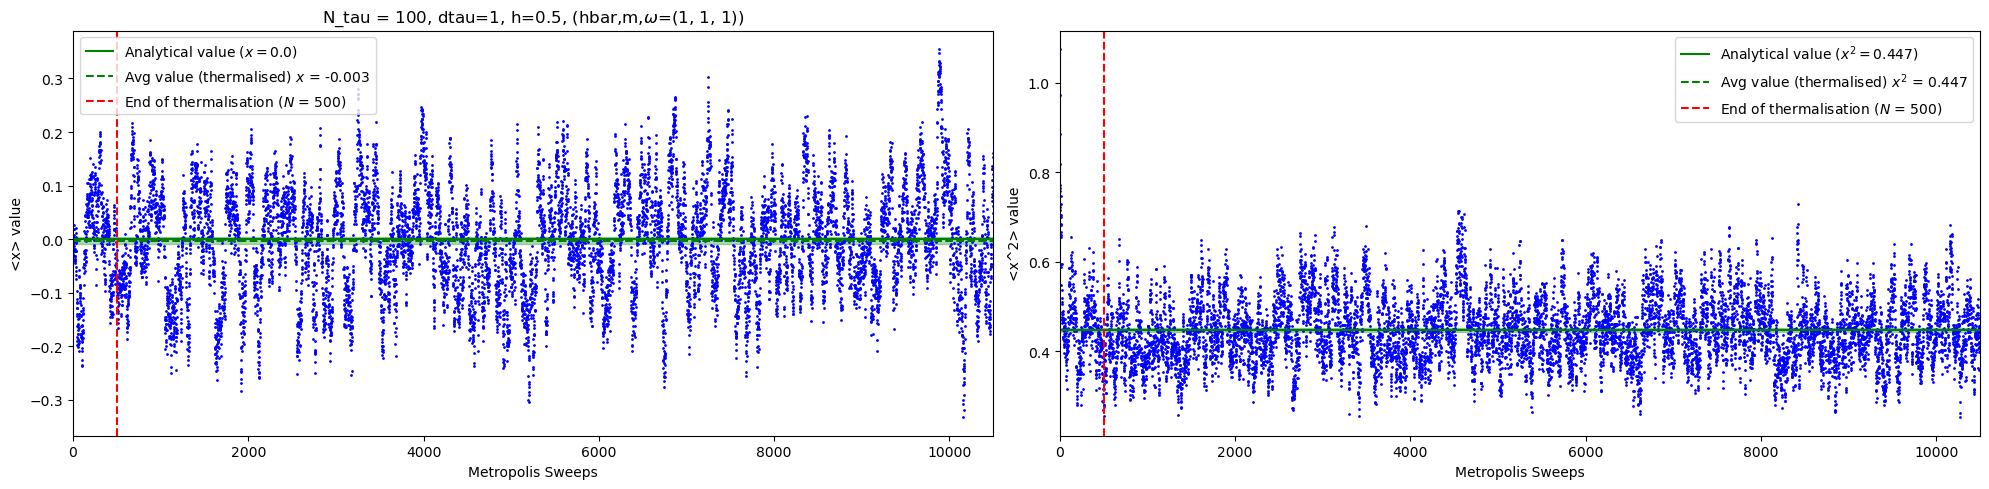

In [4]:
#Defining Parameters
h = 0.5 #step size

m = 1
omega = 1
hbar = 1

N_tau = 100 #size of the lattice
delta_tau = 1

m_tilde  = m * delta_tau #ensuring dimensionless varianbles
h_tilde = hbar * delta_tau 
omega_tilde = omega * delta_tau

N_therm = 500 #how many of the first sweeps are discarded
N_sweeps = 10000 #how many passes are repeated
samples = [] # for calculating the wavefunction

#Initialising
x = []
x_2 = []
x_analytical = 0.0

R = 1 + (omega_tilde**2/2) - omega_tilde*(np.sqrt(1+omega_tilde**2/4))

x_2_analytical = (1 / (2*m_tilde*omega_tilde*np.sqrt(1+omega_tilde**2/4))) * ((1+R**(N_tau))/(1-R**N_tau))

path = np.random.randn(N_tau)
total_acc_rate = []

V = harmonic(m_tilde, omega_tilde) #the potential is now just an input to metropolis_sweep

#Running Metropolis-Hastings Algorithm
for i in range(N_therm + N_sweeps):
    total_path, acc_rate = metropolis_sweep(path, h, m_tilde, V)
    x.append(np.mean(total_path))
    x_2.append(np.mean(total_path**2))
    total_acc_rate.append(acc_rate)
    if i >= N_therm:
        samples.append(total_path.copy())

# Slicing to get rid of first N_therm sweeps for thermalisation
x_thermalised = np.array(x[N_therm:])
x_2_thermalised = np.array(x_2[N_therm:])
total_acc_rate = np.array(total_acc_rate)

x_mean, x_naive_error = np.mean(x_thermalised), naive_error(x_thermalised)
x_2_mean, x_2_naive_error = np.mean(x_2_thermalised), naive_error(x_2_thermalised)
tau_x,  W_x,  C_x,  tau_run_x  = integrated_auto_correlation(x_thermalised)
tau_x_2, W_x_2, C_x_2, tau_run_x_2 = integrated_auto_correlation(x_2_thermalised)

#2*tau=1+2*A
x_true_error = x_naive_error * np.sqrt(2*tau_x) 
x_2_true_error = x_2_naive_error * np.sqrt(2*tau_x_2)

x_truth_value = (x_mean - x_true_error <= 0 <= x_mean + x_true_error)
x_2_truth_value = (x_2_mean - x_2_true_error <= x_2_analytical <= x_2_mean + x_2_true_error)

print(f"Acceptance rate = {np.mean(total_acc_rate)}")
print("")
print(f"<x>   = {x_mean:.4f} ± {x_true_error:.4f}  (naive {x_naive_error:.4f}) \
      theoretical value within range: {x_truth_value}")
print(f"<x^2> = {x_2_mean:.4f} ± {x_2_true_error:.4f}  (naive {x_2_naive_error:.4f}) \
      theoretical value within range: {x_2_truth_value}")
print(f"tau_int(x)   = {tau_x:.2f}  (W={W_x}),  N_eff = {N_sweeps/(2*tau_x):.0f}")
print(f"tau_int(x^2) = {tau_x_2:.2f}  (W={W_x_2}),  N_eff = {N_sweeps/(2*tau_x_2):.0f}")
print(f"<x> is {abs(x_mean)/x_true_error:.2f} true standard errors from 0")
print(f"<x^2> is {(x_2_mean - x_2_analytical) / x_2_true_error:.2f} true standard errors from the analytical value {np.round(x_2_analytical, 3)}")

# Expectation values vs. sweeps
sweeps = np.arange(len(x))
fig, ax = plt.subplots(1, 2, figsize=(20,5))
ax[0].plot(sweeps, x, 'o', color="blue", markersize=1)
ax[0].set_xlabel("Metropolis Sweeps")
ax[0].set_ylabel("<x> value")
#ax[0].set_ylim(-0.25, 0.25)
ax[0].set_xlim(0, N_therm + N_sweeps)
ax[0].axhline(y=x_analytical, color='g', linestyle='-', label = f"Analytical value ($x={x_analytical}$)")
ax[0].axhline(y=np.mean(x_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x$ = {np.round(np.mean(x_thermalised), decimals=3)}")
ax[0].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[0].set_title(rf"N_tau = {N_tau}, dtau={delta_tau}, h={h}, (hbar,m,$\omega$={hbar, m, omega})")
ax[0].legend()

ax[1].plot(sweeps, x_2, 'o', color="blue", markersize=1)
ax[1].set_xlabel("Metropolis Sweeps")
ax[1].set_ylabel("<x^2> value")
#ax[1].set_ylim(0.4, 0.6)
ax[1].set_xlim(0, N_therm + N_sweeps)
ax[1].axhline(y=x_2_analytical, color='g', linestyle='-', label = f"Analytical value ($x^2={np.round(x_2_analytical, 3)}$)")
ax[1].axhline(y=np.mean(x_2_thermalised), color='g', linestyle='--', label = f"Avg value (thermalised) $x^2$ = {np.round(np.mean(x_2_thermalised), decimals=3)}")
ax[1].axvline(N_therm, color='r', linestyle='--', label = f"End of thermalisation ($N$ = {N_therm})")
ax[1].legend()

#error bands
ax[0].axhspan(x_mean - x_true_error, x_mean + x_true_error, color="green", alpha=0.3)
ax[1].axhspan(x_2_mean - x_2_true_error, x_2_mean + x_2_true_error, color="green", alpha=0.3)

# Acceptance rate


plt.tight_layout()
plt.show()


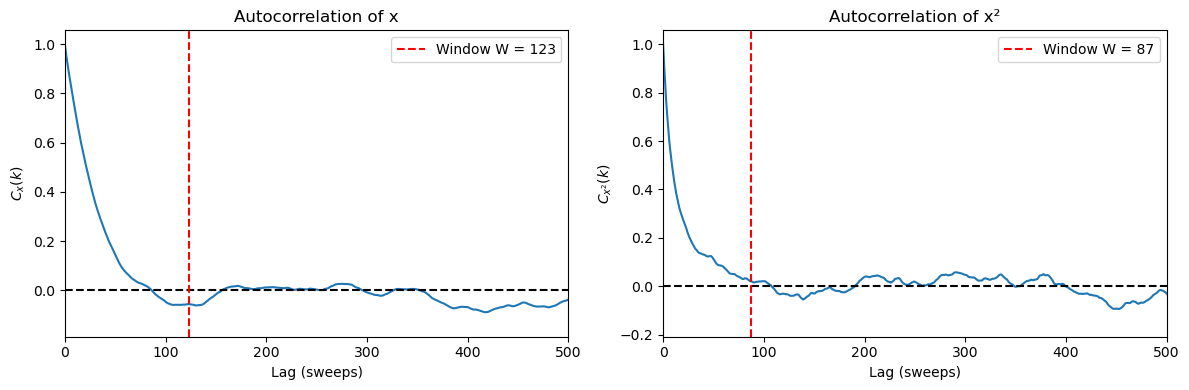

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(np.arange(len(C_x)), C_x)
ax[0].axhline(0, color="black", linestyle="--")
ax[0].axvline(W_x, color="red", linestyle="--",
              label=f"Window W = {W_x}")
ax[0].set_xlabel("Lag (sweeps)")
ax[0].set_ylabel(r"$C_x(k)$")
ax[0].set_xlim(0, 500)
ax[0].set_title("Autocorrelation of x")
ax[0].legend()

ax[1].plot(np.arange(len(C_x_2)), C_x_2)
ax[1].axhline(0, color="black", linestyle="--")
ax[1].axvline(W_x_2, color="red", linestyle="--", label=f"Window W = {W_x_2}")
ax[1].set_xlim(0, 500)
ax[1].set_xlabel("Lag (sweeps)")
ax[1].set_ylabel(r"$C_{x^2}(k)$")
ax[1].set_title("Autocorrelation of x²")
ax[1].legend()

plt.tight_layout()
plt.show()

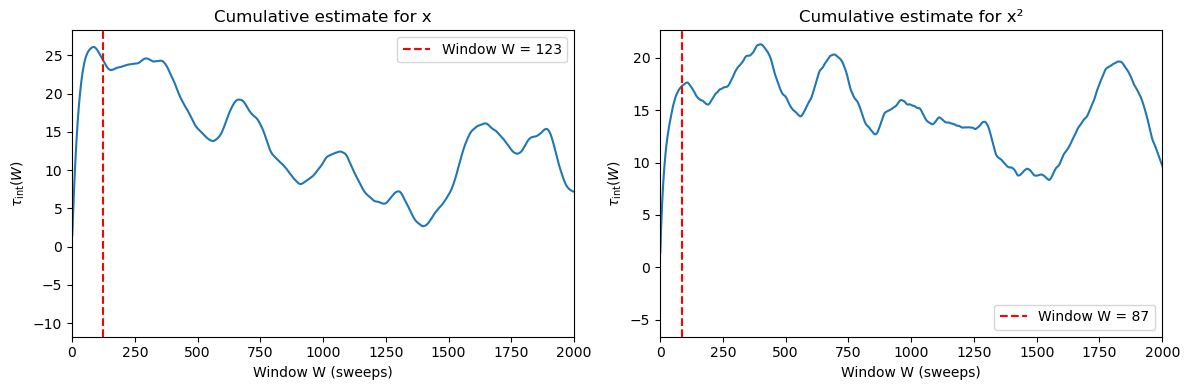

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(np.arange(1, len(tau_run_x) + 1),tau_run_x)
ax[0].axvline(W_x, color="red", linestyle="--", label=f"Window W = {W_x}")
ax[0].set_xlabel("Window W (sweeps)")
ax[0].set_xlim(0, 2000)
ax[0].set_ylabel(r"$\tau_{\mathrm{int}}(W)$")
ax[0].set_title("Cumulative estimate for x")
ax[0].legend()

ax[1].plot(np.arange(1, len(tau_run_x_2) + 1), tau_run_x_2)
ax[1].axvline(W_x_2, color="red", linestyle="--", label=f"Window W = {W_x_2}")
ax[1].set_xlabel("Window W (sweeps)")
ax[1].set_xlim(0, 2000)
ax[1].set_ylabel(r"$\tau_{\mathrm{int}}(W)$")
ax[1].set_title("Cumulative estimate for x²")
ax[1].legend()

plt.tight_layout()
plt.show()


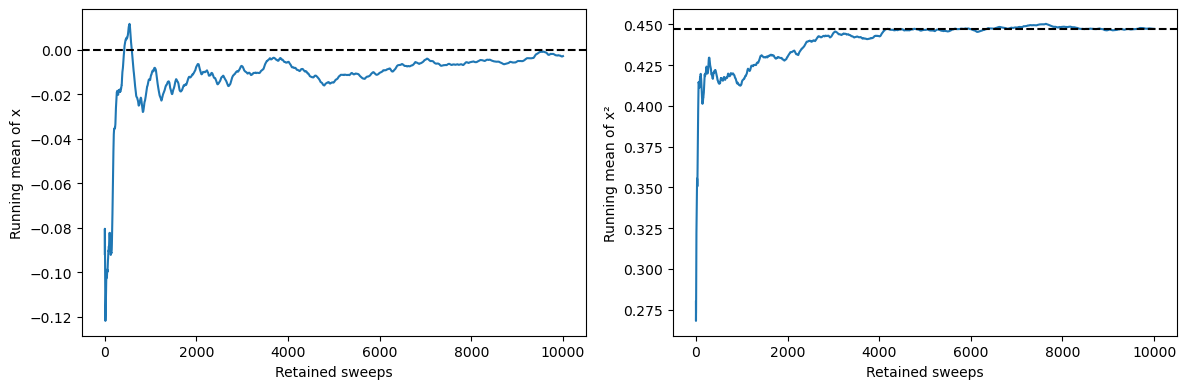

In [7]:
x_thermalised = np.asarray(x[N_therm:])
x2_thermalised = np.asarray(x_2[N_therm:])

running_x = np.cumsum(x_thermalised) / np.arange(
    1, len(x_thermalised) + 1
)

running_x2 = np.cumsum(x2_thermalised) / np.arange(
    1, len(x2_thermalised) + 1
)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(running_x)
ax[0].axhline(0, linestyle="--", color="black")
ax[0].set_xlabel("Retained sweeps")
ax[0].set_ylabel("Running mean of x")

ax[1].plot(running_x2)
ax[1].axhline(x_2_analytical, linestyle="--", color="black")
ax[1].set_xlabel("Retained sweeps")
ax[1].set_ylabel("Running mean of x²")

plt.tight_layout()
plt.show()

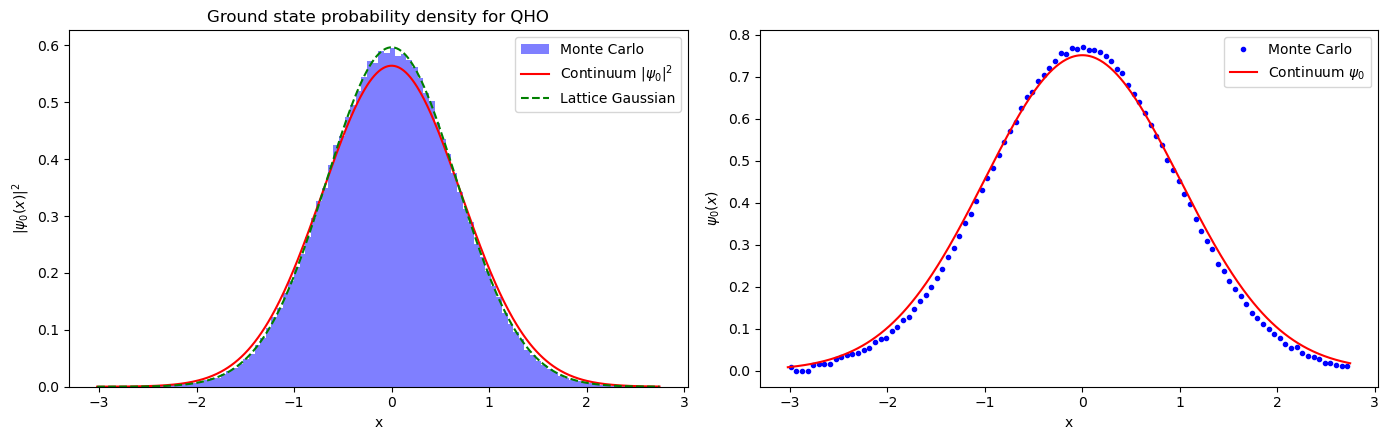

In [8]:
#continuum ground state
samples_gs = np.concatenate(samples)

x_wavefn = np.linspace(samples_gs.min(), samples_gs.max(), 500)
# continuum |psi_0|^2
psi2_cont = np.sqrt(m*omega/(np.pi*hbar)) * np.exp(-m*omega*x_wavefn**2/hbar)

#lattice-exact ground state
sigma2 = x_2_analytical
psi2_latt = np.exp(-1*(x_wavefn**2)/(2*sigma2)) / np.sqrt(2*np.pi*sigma2)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

# |psi|^2, continuum gaussian
ax[0].hist(samples_gs, bins=100, density=True, alpha=0.5, color="blue", label="Monte Carlo")
ax[0].plot(x_wavefn, psi2_cont, 'r-',  label=r"Continuum $|\psi_0|^2$")
ax[0].plot(x_wavefn, psi2_latt, 'g--', label="Lattice Gaussian")
ax[0].set_xlabel("x"); ax[0].set_ylabel(r"$|\psi_0(x)|^2$")
ax[0].set_title("Ground state probability density for QHO")
ax[0].legend()

# psi itself (positive, so it's just the square root of the density), gaussian whose variance is <x^2>
counts, edges = np.histogram(samples_gs, bins=100, density=True)
centres = 0.5*(edges[1:] + edges[:-1])
ax[1].plot(centres, np.sqrt(counts), 'o', color="blue", markersize=3, label="Monte Carlo")
ax[1].plot(x_wavefn, np.sqrt(psi2_cont), 'r-', label=r"Continuum $\psi_0$")
ax[1].set_xlabel("x"); ax[1].set_ylabel(r"$\psi_0(x)$")
ax[1].legend()

plt.tight_layout()
plt.show()


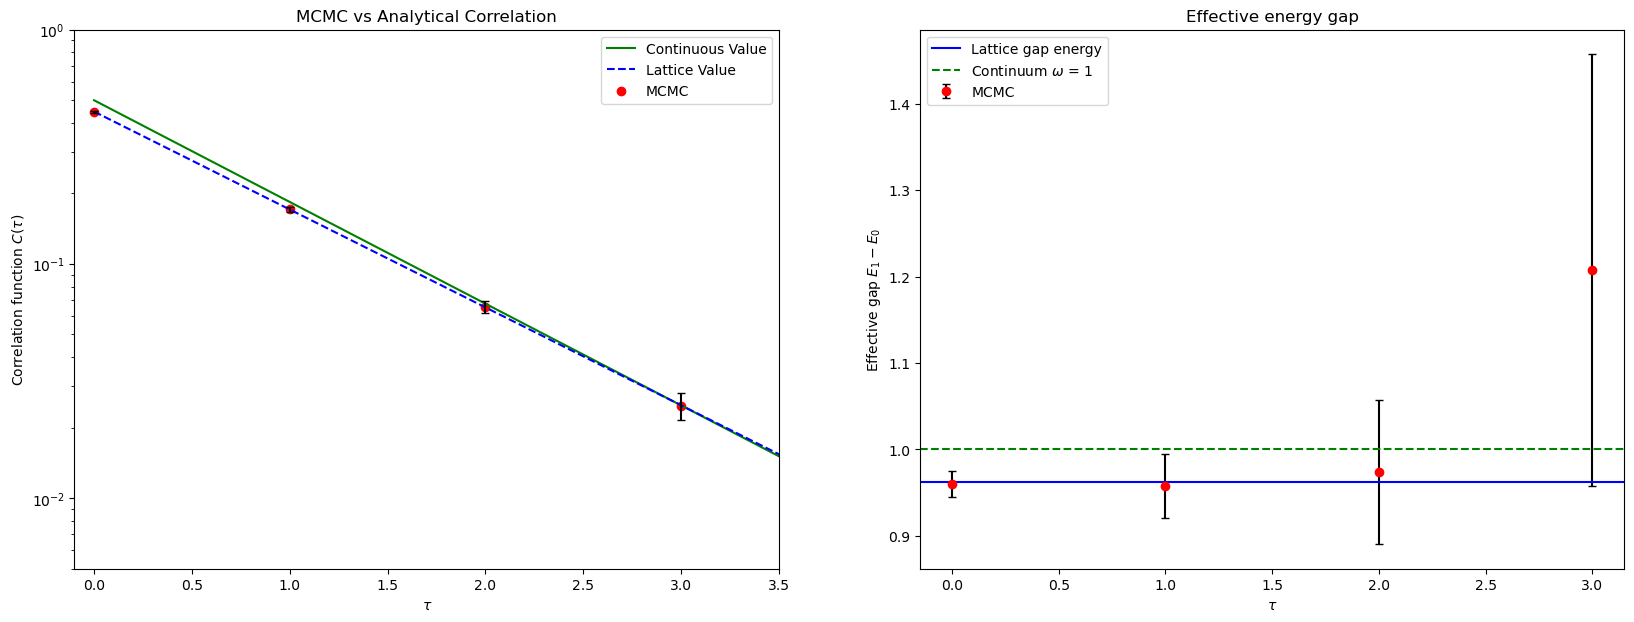

In [ ]:
n = np.arange(N_tau)
tau = n * delta_tau
C_cont = (hbar / (2*m*omega)) * np.exp(-omega*tau)
C_analytical = (R**n + R**(N_tau-n)) / (2*m_tilde*omega_tilde*np.sqrt(1+omega_tilde**2/4)*(1-R**N_tau))

x_corr, x_corr_err = jackknife(samples, B=500, statistic=correlation)
gap, gap_err = jackknife(samples, B=500, statistic=energy_gap)

#converting energy to physical units
gap, gap_err = gap/delta_tau, gap_err/delta_tau
gap_analytical = -np.log(R)/delta_tau

fig, ax = plt.subplots(1, 2, figsize = (20, 7))
ax[0].plot(tau, C_cont, '-', c='green', label="Continuous Value")
ax[0].plot(tau, C_analytical, '--', c='blue', label="Lattice Value")
ax[0].scatter(tau, x_corr, c='r', label="MCMC")
ax[0].errorbar(tau, x_corr, yerr=x_corr_err, fmt='none', c='black', capsize=3)
ax[0].set_yscale("log")
ax[0].set_xlim(-0.1, 3.5)
ax[0].set_xlabel(r'$\tau$')
ax[0].set_ylim(0.005, 1)
ax[0].set_ylabel(r"Correlation function $C(\tau)$")
ax[0].set_title("MCMC vs Analytical Correlation")
ax[0].legend()

ax[1].errorbar(np.arange(len(gap)) * delta_tau, gap, yerr=gap_err, fmt='o', c='red', ecolor='black', capsize=3, label="MCMC")
ax[1].axhline(gap_analytical, c='blue', label='Lattice gap energy')
ax[1].axhline(omega, c='green', ls='--', label=rf"Continuum $\omega$ = {omega}")
ax[1].set_xlabel(r"$\tau$")
ax[1].set_ylabel(r"Effective gap $E_1-E_0$")
ax[1].set_title("Effective energy gap")
ax[1].legend()


plt.show()


0.7932727272727272
<x> average = -0.01620103376989861
<x^2> average = 0.21612749071335086
<x^4> average = 0.11720206955308475


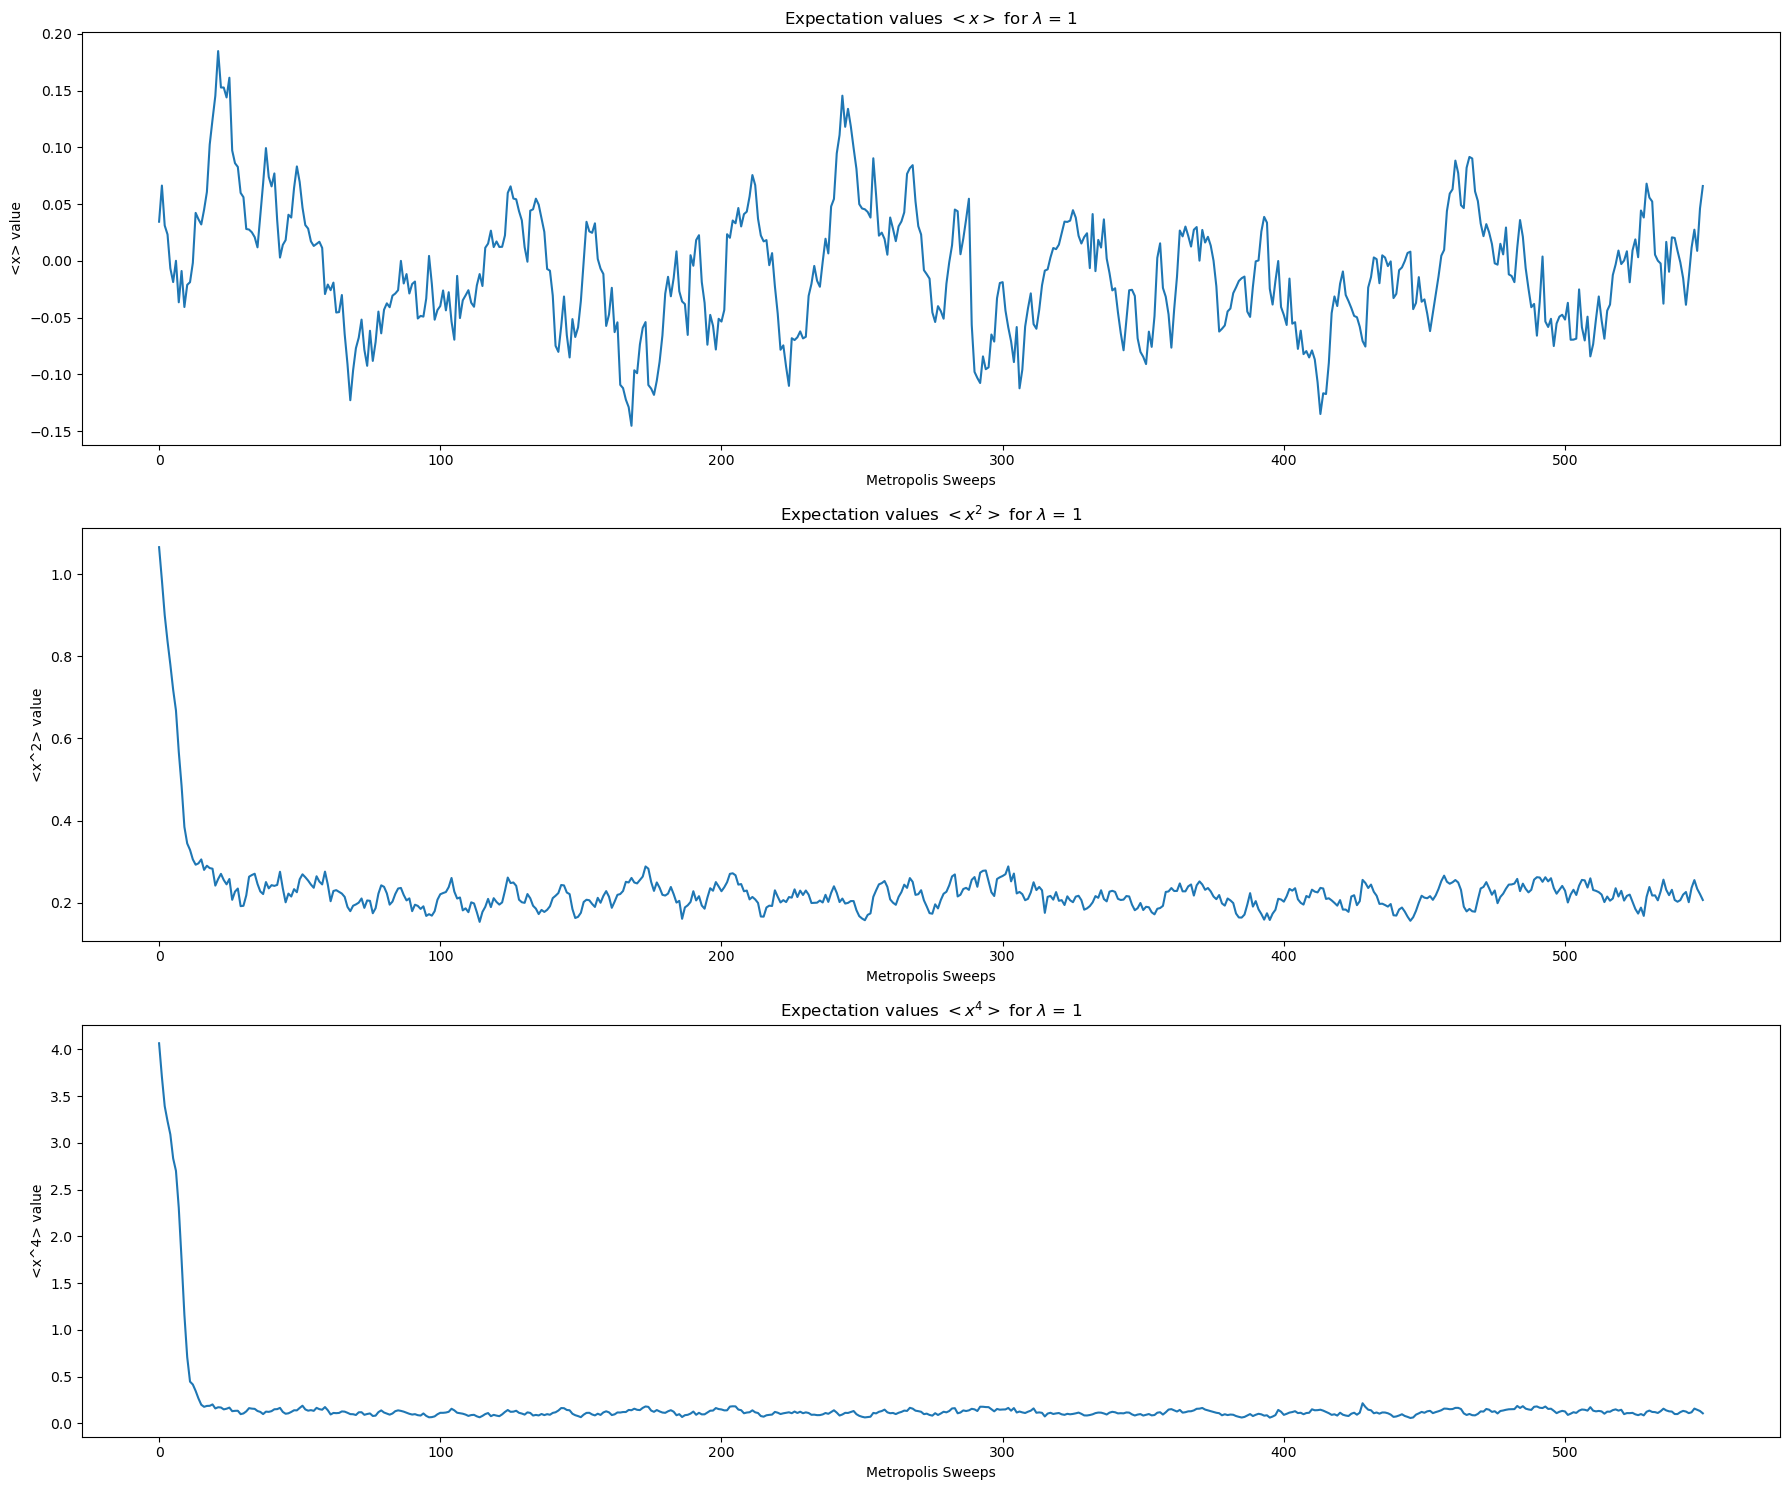

In [10]:
lam = 1 #anharmonicity parameters
h = 0.5 #step size

m = 1
omega = 1
hbar = 1

delta_tau = 1
N_tau = int(100/delta_tau) #keeping fixed physical time, so increasing N_tau as delta_tau decreases

m_tilde  = m * delta_tau #ensuring dimensionless varianbles
h_tilde = hbar * delta_tau 
omega_tilde = omega * delta_tau

N_therm = 50 #how many of the first sweeps are discarded
N_sweeps = 500 #how many passes are repeated
samples = [] # for calculating the wavefunction

#Initialising
x = []
x_2 = []
x_4 = []

path = np.random.randn(N_tau)
total_acc_rate = []
sweeps = np.arange(N_therm + N_sweeps)

V = anharmonic(m_tilde, omega_tilde, lam) #the potential is now just an input to metropolis_sweep

for i in range(N_therm + N_sweeps):
    total_path, acc_rate = metropolis_sweep(path, h, m_tilde, V)

    x.append(np.mean(total_path))
    x_2.append(np.mean(total_path**2))
    x_4.append(np.mean(total_path**4))

    total_acc_rate.append(acc_rate)
    if i >= N_therm:
        samples.append(total_path.copy())

x_thermalised = np.array(x[N_therm:])
x_2_thermalised = np.array(x_2[N_therm:])
x_4_thermalised = np.array(x_4[N_therm:])
total_acc_rate = np.array(total_acc_rate)

x_mean, x_naive_error = np.mean(x_thermalised), naive_error(x_thermalised)
x_2_mean, x_2_naive_error = np.mean(x_2_thermalised), naive_error(x_2_thermalised)
x_4_mean, x_4_naive_error = np.mean(x_4_thermalised), naive_error(x_4_thermalised)
tau_x,  W_x,  C_x,  tau_run_x  = integrated_auto_correlation(x_thermalised)
tau_x_2, W_x_2, C_x_2, tau_run_x_2 = integrated_auto_correlation(x_2_thermalised)
x_4_tau, W_x_4, C_x_4, tau_run_x_4 = integrated_auto_correlation(x_4_thermalised)

#2*tau=1+2*A
x_true_error = x_naive_error * np.sqrt(2*tau_x) 
x_2_true_error = x_2_naive_error * np.sqrt(2*tau_x_2)
x_4_true_error = x_4_naive_error * np.sqrt(2*x_4_tau)

E_0_anhar = (m_tilde * omega_tilde**2 * x_2_mean
             + 3 * lam * m_tilde**2 * omega_tilde**3 * x_4_mean) / delta_tau #virial estimator, converted to physical units
lambda_values = [0, 1, 50, 1000]

print(total_acc_rate.mean())
print("<x> average =" , x_mean)
print("<x^2> average =" , x_2_mean)
print("<x^4> average =" , x_4_mean)

fig, ax = plt.subplots(3, 1, figsize=(18,15))
ax[0].plot(sweeps, x)
ax[0].set_title(rf"Expectation values $<x>$ for $\lambda$ = {lam}")
ax[0].set_xlabel("Metropolis Sweeps")
ax[0].set_ylabel("<x> value")

ax[1].plot(sweeps, x_2)
ax[1].set_title(rf"Expectation values $<x^2>$ for $\lambda$ = {lam}")
ax[1].set_xlabel("Metropolis Sweeps")
ax[1].set_ylabel("<x^2> value")

ax[2].plot(sweeps, x_4)
ax[2].set_title(rf"Expectation values $<x^4>$ for $\lambda$ = {lam}")
ax[2].set_xlabel("Metropolis Sweeps")
ax[2].set_ylabel("<x^4> value")
plt.tight_layout()
plt.show()

In [11]:
N_therm = 2000 #how many of the first sweeps are discarded (small delta_tau needs much longer to equilibrate)
N_sweeps = 10000 #how many passes are repeated

delta_tau_values = [0.1, 0.25, 0.5, 1.0]
lambda_values = [0]

energy_results = {lam: [] for lam in lambda_values}
energy_errors = {lam: [] for lam in lambda_values}
delta_tau_results = {lam: [] for lam in lambda_values}

for i in lambda_values:
    for j in delta_tau_values:
        lam = i
        delta_tau = j
        N_tau = int(50/delta_tau) #beta = 50 is plenty to isolate the ground state (gap = 1)
        m_tilde  = m * delta_tau
        h_tilde = hbar * delta_tau 
        omega_tilde = omega * delta_tau
        h = 2.5 / np.sqrt(m_tilde * (2 + omega_tilde**2)) # step ~2.5x the width a single site fluctuates by, so it scales with delta_tau

        V = anharmonic(m_tilde, omega_tilde, lam)

        path = np.random.randn(N_tau)
        total_acc_rate = []
        x_2 = []
        x_4 = []

        for k in range(N_therm + N_sweeps):
            total_path, acc_rate = metropolis_sweep(path, h, m_tilde, V)
            x_2.append(np.mean(total_path**2))
            x_4.append(np.mean(total_path**4))
            total_acc_rate.append(acc_rate)

        x_2_mean = np.mean(x_2[N_therm:])
        x_4_mean = np.mean(x_4[N_therm:])
        #E_0_anhar = (delta_tau**2 * x_2_mean) + (3 * lam * delta_tau**4 * x_4_mean)
        # virial estimator in lattice units, divided by delta_tau to convert to physical units
        E_0_anhar = (m_tilde * omega_tilde**2 * x_2_mean
                     + 3 * lam * m_tilde**2 * omega_tilde**3 * x_4_mean) / delta_tau

        # same estimator sweep-by-sweep, to get an error bar that accounts for autocorrelation
        E_series = (m_tilde * omega_tilde**2 * np.array(x_2[N_therm:])
                    + 3 * lam * m_tilde**2 * omega_tilde**3 * np.array(x_4[N_therm:])) / delta_tau
        tau_E = integrated_auto_correlation(E_series)[0]
        E_0_err = naive_error(E_series) * np.sqrt(2 * tau_E)

        energy_results[lam].append(E_0_anhar)
        energy_errors[lam].append(E_0_err)
        delta_tau_results[lam].append(delta_tau)
        print(f"Lambda: {lam}, Delta_tau: {delta_tau}, E_0_anhar: {E_0_anhar:.4f} ± {E_0_err:.4f}, "
              f"tau_int: {tau_E:.1f}, h: {h:.2f}, Acceptance Rate: {np.mean(total_acc_rate):.3f}")

Lambda: 0, Delta_tau: 0.1, E_0_anhar: 0.5049 ± 0.0238, tau_int: 241.9, h: 5.58, Acceptance Rate: 0.557
Lambda: 0, Delta_tau: 0.25, E_0_anhar: 0.5164 ± 0.0084, tau_int: 30.1, h: 3.48, Acceptance Rate: 0.557
Lambda: 0, Delta_tau: 0.5, E_0_anhar: 0.4907 ± 0.0044, tau_int: 9.1, h: 2.36, Acceptance Rate: 0.557
Lambda: 0, Delta_tau: 1.0, E_0_anhar: 0.4466 ± 0.0029, tau_int: 3.9, h: 1.44, Acceptance Rate: 0.556


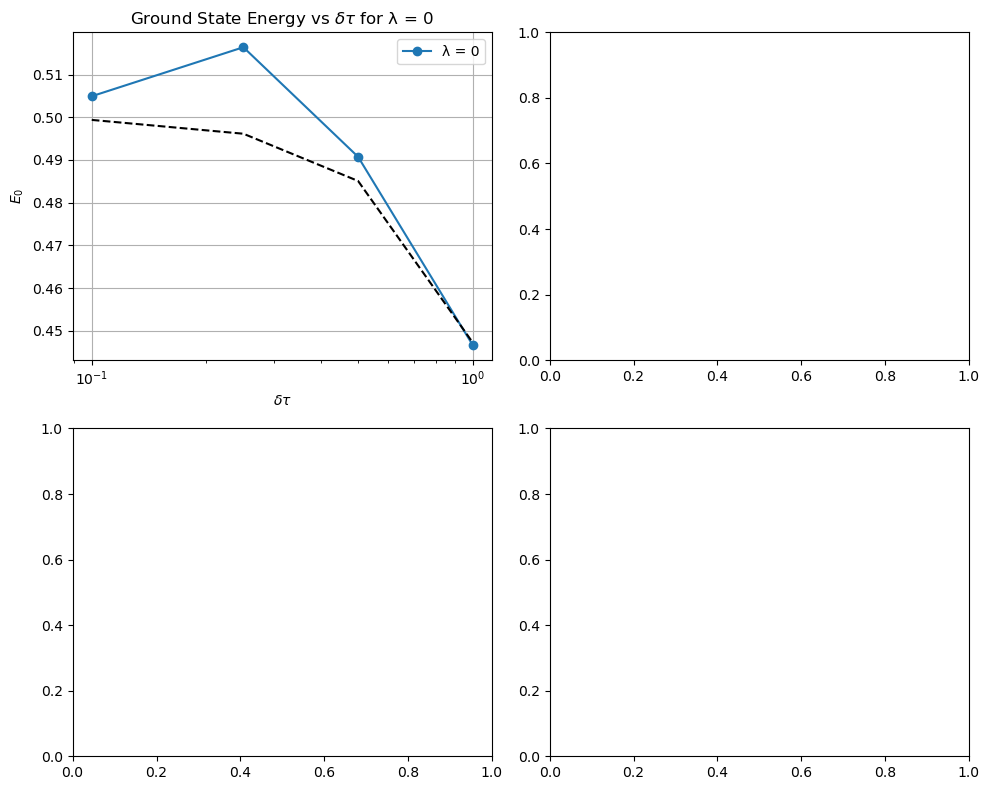

In [12]:
E_0_analytical = []
for i in delta_tau_values:
    E_0_analytical.append(1/np.sqrt(4+i**2))

fig, ax = plt.subplots(2, 2, figsize=(10, 8))
for idx, lam in enumerate(lambda_values):
    ax[idx//2, idx%2].semilogx(delta_tau_results[lam], energy_results[lam], marker='o', label=f'λ = {lam}')
    ax[idx//2, idx%2].set_title(fr'Ground State Energy vs $\delta\tau$ for λ = {lam}')
    ax[idx//2, idx%2].set_xlabel(fr'$\delta\tau$')
    ax[idx//2, idx%2].set_ylabel(fr'$E_0$')
    ax[idx//2, idx%2].legend()
    ax[idx//2, idx%2].grid()

ax[0,0].plot(delta_tau_values, E_0_analytical, 'k--', label='Analytical (λ=0)')
plt.tight_layout()
plt.show()

## Continuum extrapolation (harmonic oscillator)

**What changes with $a = \delta\tau$.** Every quantity measured on the lattice differs from its continuum value by discretisation errors. The kinetic term is a symmetric finite difference, so the leading error is $\mathcal{O}(a^2)$. For the harmonic oscillator ($m=\omega=\hbar=1$) the lattice results are known exactly:

$$E_0(a) = \frac{1}{2\sqrt{1+a^2/4}} \approx \tfrac12\left(1 - \tfrac{a^2}{8}\right), \qquad \cosh\!\big(a\,\Delta E(a)\big) = 1 + \tfrac{a^2}{2} \;\Rightarrow\; \Delta E(a) \approx 1 - \tfrac{a^2}{24}$$

**Why not just use tiny $a$.** At fixed physical length $\beta$, $N_\tau = \beta/a$ grows, and the autocorrelation time $\tau_{\rm int}$ grows like a power of $1/a$, because neighbouring sites become strongly coupled and single-site updates move the path only slowly. The cost of an independent sample (sites × sweeps needed) therefore grows even faster. Both are measured below.

**The method.** Simulate at several $a$ well away from 0, fit $E(a) = E_{\rm cont} + c\,a^2$, and take the **intercept** at $a^2=0$ as the continuum value. The slope $c$ measures the size of the discretisation error and can be checked against $-1/16$ for $E_0$ and $-1/24$ for $\Delta E$.

**Choosing the range of $a$.** If $a$ is too large, the $a^4$ terms matter, the points bend away from a straight line in $a^2$, and the intercept is biased. If only very small $a$ are used, the errors are large and the runs expensive. The window study below fits $a \le a_{\max}$ for increasing $a_{\max}$. A good choice is the largest $a_{\max}$ for which the intercept is still stable and $\chi^2/\text{dof} \approx 1$.

Note that $\tau$ on the correlation and effective-energy plots is a Euclidean time **separation along one path**, $\tau = n a$. It is not the lattice spacing, and not Monte Carlo time, which is measured in sweeps.

In [13]:
# Continuum extrapolation, step 1: simulate the harmonic oscillator at several lattice spacings a = delta_tau
import time
from functions import gap_statistic, fit_continuum

beta_ce = 50                      # physical Euclidean time extent, kept fixed as a changes
N_therm_ce = 2000                 # thermalisation sweeps (small a needs many)
N_sweeps_ce = 20000               # measurement sweeps
a_scan = np.array([0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5])
tau_gap = 1.0                     # physical separation used to read the gap from C(tau)

def run_at_spacing(a):
    # kept inside a function so it doesn't overwrite delta_tau, m_tilde, h, ... used in earlier cells
    N = int(round(beta_ce / a))
    m_t, w_t = m * a, omega * a
    step = 2.5 / np.sqrt(m_t * (2 + w_t**2))   # step size scaled with a
    V_a = harmonic(m_t, w_t)

    p = np.random.randn(N)
    x2_series, paths, acc = [], [], []
    t_start = time.time()
    for k in range(N_therm_ce + N_sweeps_ce):
        p, r = metropolis_sweep(p, step, m_t, V_a)
        acc.append(r)
        if k >= N_therm_ce:
            x2_series.append(np.mean(p**2))
            paths.append(p.copy())
    runtime = time.time() - t_start

    # ground state energy from the virial estimator (physical units), autocorrelation-corrected error
    E_series = m_t * w_t**2 * np.array(x2_series) / a
    tau_E = integrated_auto_correlation(E_series)[0]
    E0 = E_series.mean()
    E0_err = naive_error(E_series) * np.sqrt(2 * tau_E)

    # energy gap from the slope of ln C(tau), jackknife error (blocks of 500 sweeps >> tau_int)
    n_gap = max(1, int(round(tau_gap / a)))
    gap, gap_err = jackknife(paths, B=500, statistic=lambda S: gap_statistic(S, n_gap, a))

    return dict(E0=E0, E0_err=E0_err, gap=gap, gap_err=gap_err,
                tau_int=tau_E, runtime=runtime, acc=np.mean(acc))

ce_results = []
for a in a_scan:
    res = run_at_spacing(a)
    ce_results.append(res)
    print(f"a = {a:<4}: E_0 = {res['E0']:.4f} ± {res['E0_err']:.4f}  (lattice exact {1/np.sqrt(4 + a**2):.4f}),  "
          f"E_1-E_0 = {res['gap']:.4f} ± {res['gap_err']:.4f}  (lattice exact {np.arccosh(1 + a**2/2)/a:.4f}),  "
          f"tau_int = {res['tau_int']:.1f},  acc = {res['acc']:.2f},  {res['runtime']:.0f}s")

E0_ce      = np.array([r['E0'] for r in ce_results])
E0_err_ce  = np.array([r['E0_err'] for r in ce_results])
gap_ce     = np.array([r['gap'] for r in ce_results])
gap_err_ce = np.array([r['gap_err'] for r in ce_results])
tau_int_ce = np.array([r['tau_int'] for r in ce_results])
runtime_ce = np.array([r['runtime'] for r in ce_results])

a = 0.2 : E_0 = 0.5024 ± 0.0066  (lattice exact 0.4975),  E_1-E_0 = 0.9992 ± 0.0183  (lattice exact 0.9983),  tau_int = 43.1,  acc = 0.56,  60s
a = 0.3 : E_0 = 0.4953 ± 0.0044  (lattice exact 0.4945),  E_1-E_0 = 0.9891 ± 0.0129  (lattice exact 0.9963),  tau_int = 19.7,  acc = 0.56,  3119s
a = 0.4 : E_0 = 0.4877 ± 0.0036  (lattice exact 0.4903),  E_1-E_0 = 1.0025 ± 0.0101  (lattice exact 0.9935),  tau_int = 12.7,  acc = 0.56,  477s
a = 0.5 : E_0 = 0.4869 ± 0.0032  (lattice exact 0.4851),  E_1-E_0 = 0.9765 ± 0.0076  (lattice exact 0.9899),  tau_int = 9.8,  acc = 0.56,  74s
a = 0.7 : E_0 = 0.4746 ± 0.0025  (lattice exact 0.4719),  E_1-E_0 = 0.9700 ± 0.0058  (lattice exact 0.9806),  tau_int = 5.7,  acc = 0.56,  9s
a = 1.0 : E_0 = 0.4503 ± 0.0021  (lattice exact 0.4472),  E_1-E_0 = 0.9619 ± 0.0056  (lattice exact 0.9624),  tau_int = 4.2,  acc = 0.56,  6s
a = 1.5 : E_0 = 0.4007 ± 0.0018  (lattice exact 0.4000),  E_1-E_0 = 0.9202 ± 0.0058  (lattice exact 0.9242),  tau_int = 3.0,  acc = 0.56, 

 a_max |      E_0 continuum chi2/dof |      gap continuum chi2/dof
   0.4 | 0.5064 ± 0.0071        0.03 | 0.9886 ± 0.0201        0.44
   0.5 | 0.5005 ± 0.0050        0.72 | 1.0079 ± 0.0140        1.12
   0.7 | 0.4990 ± 0.0032        0.53 | 0.9998 ± 0.0086        0.93
   1.0 | 0.4985 ± 0.0023        0.41 | 0.9910 ± 0.0060        1.20
   1.5 | 0.4959 ± 0.0017        0.91 | 0.9909 ± 0.0044        0.96


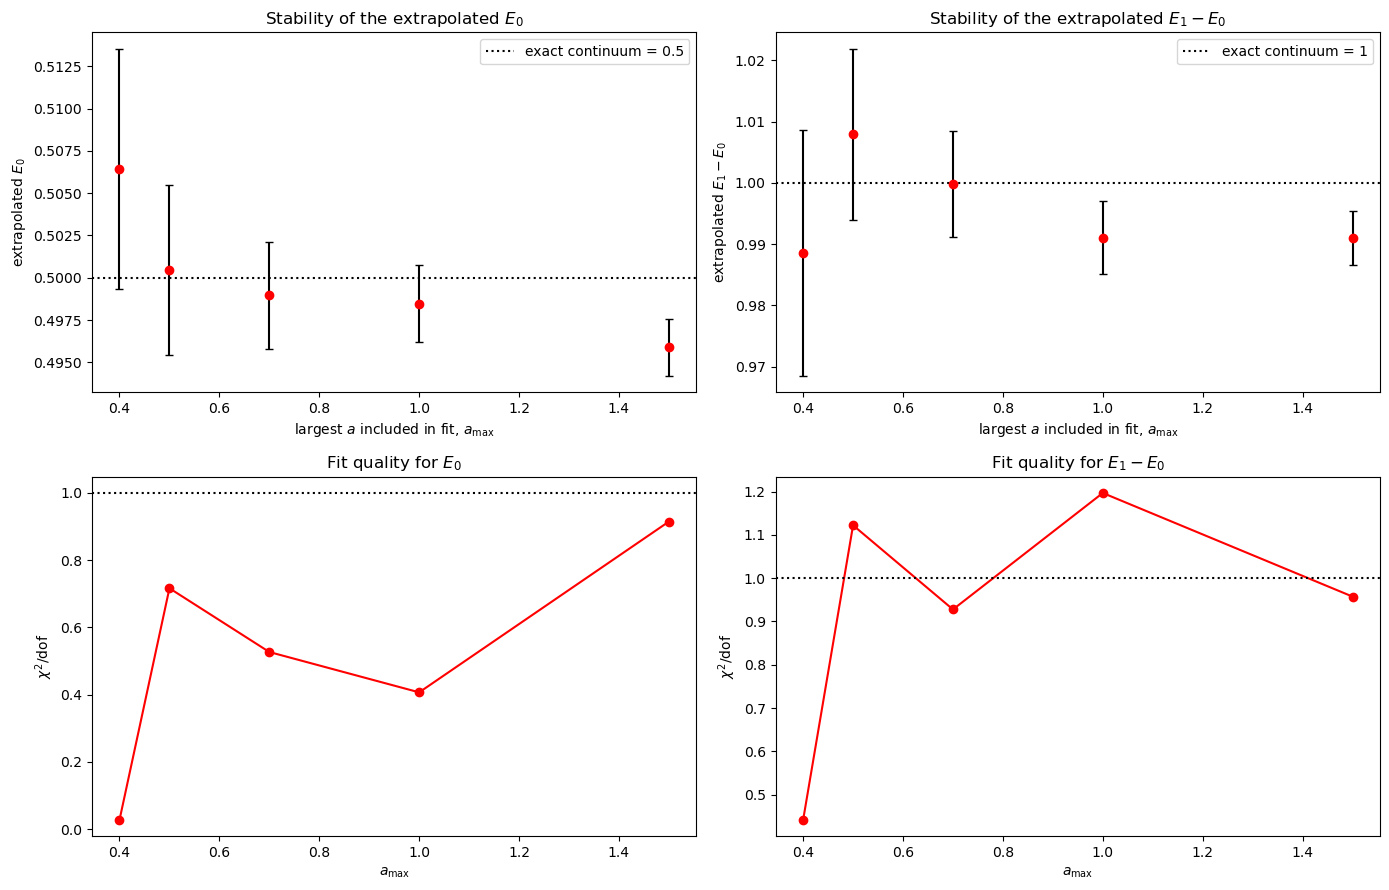

tau_int ~ a^-1.31,   cost per independent sample ~ a^-3.90


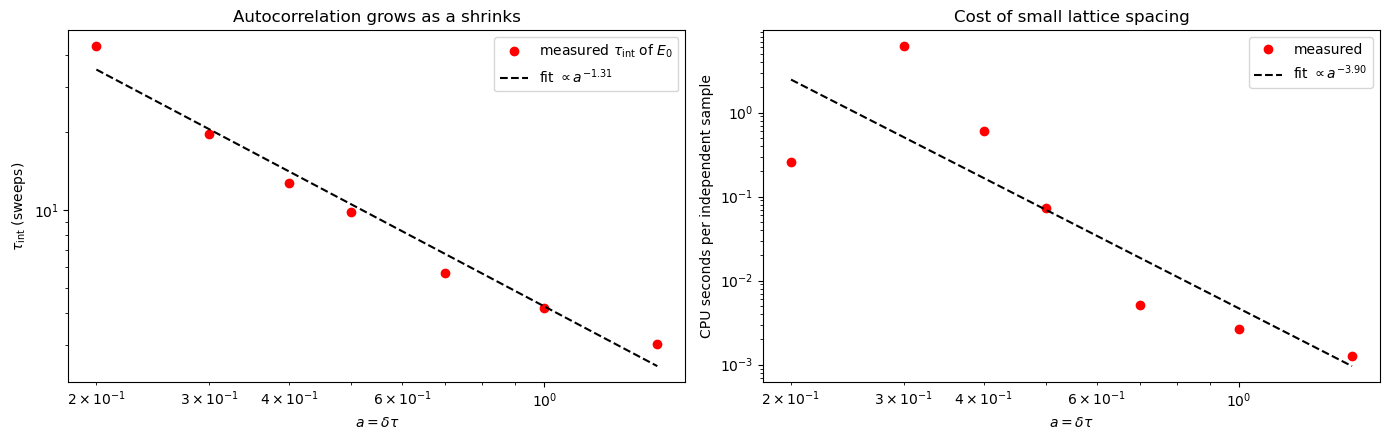

In [14]:
# Continuum extrapolation, step 2: which range of a should go into the fit?
# Fit only the points with a <= a_max, for increasing a_max, and watch the intercept and chi^2/dof.

a_max_list = a_scan[2:]           # need at least 3 points for a 2-parameter fit with dof > 0
window = {"E0": [], "gap": []}

print(f"{'a_max':>6} | {'E_0 continuum':>18} {'chi2/dof':>8} | {'gap continuum':>18} {'chi2/dof':>8}")
for a_max in a_max_list:
    mask = a_scan <= a_max + 1e-12
    for key, y, y_err in [("E0", E0_ce, E0_err_ce), ("gap", gap_ce, gap_err_ce)]:
        y_cont, y_cont_err, coef, cov, chi2_dof = fit_continuum(a_scan[mask], y[mask], y_err[mask])
        window[key].append((y_cont, y_cont_err, chi2_dof))
    (e, ee, ce), (g, ge, cg) = window["E0"][-1], window["gap"][-1]
    print(f"{a_max:>6} | {e:.4f} ± {ee:.4f}    {ce:>8.2f} | {g:.4f} ± {ge:.4f}    {cg:>8.2f}")

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

for col, key, exact, name in [(0, "E0", 0.5 * omega, r"$E_0$"), (1, "gap", omega, r"$E_1 - E_0$")]:
    vals = np.array(window[key])
    ax[0, col].errorbar(a_max_list, vals[:, 0], yerr=vals[:, 1], fmt='o', c='red', ecolor='black', capsize=3)
    ax[0, col].axhline(exact, color='k', ls=':', label=f"exact continuum = {exact}")
    ax[0, col].set_xlabel(r"largest $a$ included in fit, $a_{\max}$")
    ax[0, col].set_ylabel(f"extrapolated {name}")
    ax[0, col].set_title(f"Stability of the extrapolated {name}")
    ax[0, col].legend()

    ax[1, col].plot(a_max_list, vals[:, 2], 'o-', c='red')
    ax[1, col].axhline(1, color='k', ls=':')
    ax[1, col].set_xlabel(r"$a_{\max}$")
    ax[1, col].set_ylabel(r"$\chi^2/\mathrm{dof}$")
    ax[1, col].set_title(f"Fit quality for {name}")

plt.tight_layout()
plt.show()

# Cost of each lattice spacing: autocorrelation time and CPU time per independent sample
cost = runtime_ce / N_sweeps_ce * 2 * tau_int_ce      # seconds per independent sample
p_tau, A_tau = np.polyfit(np.log(a_scan), np.log(tau_int_ce), 1)   # fit tau_int ~ a^p
p_cost, A_cost = np.polyfit(np.log(a_scan), np.log(cost), 1)
print(f"tau_int ~ a^{p_tau:.2f},   cost per independent sample ~ a^{p_cost:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].loglog(a_scan, tau_int_ce, 'o', c='red', label=r"measured $\tau_{\mathrm{int}}$ of $E_0$")
ax[0].loglog(a_scan, np.exp(A_tau) * a_scan**p_tau, 'k--', label=rf"fit $\propto a^{{{p_tau:.2f}}}$")
ax[0].set_xlabel(r"$a = \delta\tau$")
ax[0].set_ylabel(r"$\tau_{\mathrm{int}}$ (sweeps)")
ax[0].set_title("Autocorrelation grows as a shrinks")
ax[0].legend()

ax[1].loglog(a_scan, cost, 'o', c='red', label="measured")
ax[1].loglog(a_scan, np.exp(A_cost) * a_scan**p_cost, 'k--', label=rf"fit $\propto a^{{{p_cost:.2f}}}$")
ax[1].set_xlabel(r"$a = \delta\tau$")
ax[1].set_ylabel("CPU seconds per independent sample")
ax[1].set_title("Cost of small lattice spacing")
ax[1].legend()

plt.tight_layout()
plt.show()

$E_0$: continuum limit = 0.4985 ± 0.0023 (exact 0.5),  slope c = -0.0483 ± 0.0035 (expected -0.0625),  chi2/dof = 0.41,  -0.7 sigma from exact
$E_1 - E_0$: continuum limit = 0.9910 ± 0.0060 (exact 1),  slope c = -0.0316 ± 0.0093 (expected -0.0417),  chi2/dof = 1.20,  -1.5 sigma from exact


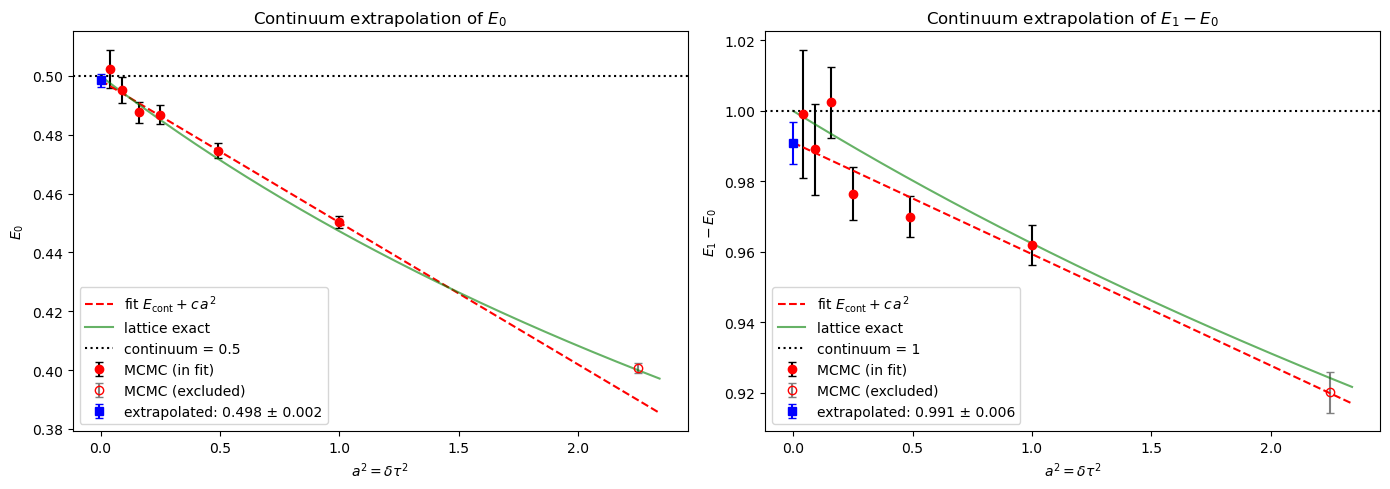

In [15]:
# Continuum extrapolation, step 3: final fit using the window chosen from the study above
a_fit_max = 1.0                   # largest a included -- choose this from the stability / chi^2 plots above

mask = a_scan <= a_fit_max + 1e-12
a2_fine = np.linspace(0, (a_scan.max() * 1.02)**2, 300)
a_fine = np.sqrt(a2_fine)
E0_lattice_exact = omega / (2 * np.sqrt(1 + (omega * a_fine)**2 / 4))
gap_lattice_exact = np.arccosh(1 + (omega * a_fine)**2 / 2) / np.where(a_fine > 0, a_fine, 1)
gap_lattice_exact[0] = omega

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for axis, y, y_err, exact_curve, continuum, expected_slope, name in [
        (ax[0], E0_ce, E0_err_ce, E0_lattice_exact, 0.5 * omega, -omega**3 / 16, r"$E_0$"),
        (ax[1], gap_ce, gap_err_ce, gap_lattice_exact, omega, -omega**3 / 24, r"$E_1 - E_0$")]:

    y_cont, y_cont_err, coef, cov, chi2_dof = fit_continuum(a_scan[mask], y[mask], y_err[mask])
    print(f"{name}: continuum limit = {y_cont:.4f} ± {y_cont_err:.4f} (exact {continuum}),  "
          f"slope c = {coef[0]:.4f} ± {np.sqrt(cov[0, 0]):.4f} (expected {expected_slope:.4f}),  "
          f"chi2/dof = {chi2_dof:.2f},  {(y_cont - continuum) / y_cont_err:+.1f} sigma from exact")

    axis.errorbar(a_scan[mask]**2, y[mask], yerr=y_err[mask], fmt='o', c='red', ecolor='black', capsize=3,
                  label="MCMC (in fit)")
    if (~mask).any():
        axis.errorbar(a_scan[~mask]**2, y[~mask], yerr=y_err[~mask], fmt='o', mfc='none', c='red',
                      ecolor='grey', capsize=3, label="MCMC (excluded)")
    axis.plot(a2_fine, np.polyval(coef, a2_fine), 'r--', label=r"fit $E_{\mathrm{cont}} + c\,a^2$")
    axis.errorbar([0], [y_cont], yerr=[y_cont_err], fmt='s', c='blue', capsize=3,
                  label=f"extrapolated: {y_cont:.3f} ± {y_cont_err:.3f}")
    axis.plot(a2_fine, exact_curve, 'g-', alpha=0.6, label="lattice exact")
    axis.axhline(continuum, color='k', ls=':', label=f"continuum = {continuum}")
    axis.set_xlabel(r"$a^2 = \delta\tau^2$")
    axis.set_ylabel(name)
    axis.set_title(f"Continuum extrapolation of {name}")
    axis.legend()

plt.tight_layout()
plt.show()